# ETS SC - Studi Kasus: Optimasi Rute Pengambilan Barang pada Gudang

## Pendahuluan



---

**1. Latar Belakang**

Sebuah perusahaan distribusi sepatu memiliki gudang yang menyimpan berbagai jenis produk dengan ukuran yang berbeda-beda. Setiap hari, perusahaan menerima pesanan dari pelanggan yang harus diproses dan disiapkan untuk pengiriman. Untuk memenuhi pesanan tersebut, petugas gudang melakukan aktivitas *order picking*, yaitu mengambil barang dari lokasi penyimpanan berdasarkan daftar pesanan yang diterima.

Gudang memiliki banyak lokasi penyimpanan yang tersebar di beberapa area:
* **Posisi & Koordinat:** Setiap lokasi penyimpanan memiliki posisi koordinat 3 dimensi $(x, y, z)$.
* **Informasi Pesanan:** Setiap pesanan berisi informasi kode produk, ukuran, dan jumlah barang yang harus diambil.
* **Pengelompokan (Picking Wave):** Pesanan dikelompokkan ke dalam beberapa *picking wave* agar proses pengambilan barang dapat dilakukan secara terorganisasi.

**Permasalahan Utama:**  
Rute pengambilan barang yang digunakan petugas saat ini belum tentu efisien. Urutan pengambilan yang kurang tepat dapat menyebabkan petugas menempuh jarak perjalanan lebih jauh, sehingga waktu operasional meningkat dan produktivitas gudang menurun.

**Solusi:**  
Perusahaan ingin menerapkan algoritma optimasi guna menentukan urutan kunjungan lokasi penyimpanan yang menghasilkan total jarak perjalanan seminimal mungkin.

---

**2. Deskripsi Permasalahan & Dataset**

Diberikan dataset yang terdiri atas beberapa file utama:
* **`Picking_Wave.csv`**: Memuat daftar pesanan dan kebutuhan barang pada setiap gelombang pengambilan barang.
* **`Storage_Location.csv`**: Memuat daftar lokasi penyimpanan beserta koordinat $(x, y, z)$ di dalam gudang.
* **`Support_Point_Navigation`**: Memuat titik awal (depot) dan titik navigasi petugas.

**Ketentuan Skenario Pengujian**
1. **Pemilihan Skenario:** Pilih **satu *picking wave*** sebagai skenario pengujian.
2. **Penentuan Lokasi:** Tentukan seluruh lokasi penyimpanan yang perlu dikunjungi untuk memenuhi kebutuhan barang pada *picking wave* tersebut.
3. **Rute Perjalanan:**
   * Petugas memulai perjalanan dari **titik awal (depot)** yang telah ditentukan.
   * Petugas mengunjungi seluruh lokasi penyimpanan yang diperlukan.
   * Petugas kembali ke titik awal setelah seluruh barang berhasil diambil.
---

**3. Metodologi Algoritma**

Penyelesaian masalah dilakukan menggunakan dua algoritma untuk membandingkan tingkat efisiensi rute yang dihasilkan:

**A. Genetic Algorithm (GA) — Algoritma Utama**
* Menggunakan pendekatan evolusi kandidat solusi (populasi, seleksi, *crossover*, dan mutasi).
* Bertujuan mencari urutan kunjungan lokasi yang meminimalkan total jarak perjalanan secara global.

**B. Nearest Neighbor (NN) — Algoritma Pembanding**
* Menggunakan pendekatan *greedy* dengan memilih lokasi yang belum dikunjungi yang memiliki jarak terdekat dari posisi petugas saat ini.
* Proses diulang hingga seluruh lokasi yang diperlukan telah dikunjungi sebelum kembali ke titik awal.

---

**4. Luaran & Evaluasi**

1. **Implementasi:** Mengembangkan program optimasi rute berbasis Genetic Algorithm dan Nearest Neighbor.
2. **Visualisasi / Traversal:** Menghasilkan urutan rute kunjungan beserta total jarak tempuh untuk *picking wave* yang dipilih.
3. **Analisis Komparatif:** Membandingkan total jarak perjalanan dan efisiensi rute antara Genetic Algorithm dan Nearest Neighbor.

## Import Library

In [ ]:
import numpy as np
import pandas as pd
import random
import ast
import matplotlib.pyplot as plt
import matplotlib.lines as mlines
import re
import heapq

###Load Data

In [ ]:
print("Memuat data...")
storage_location = "https://raw.githubusercontent.com/daniel3200u/ETSSoftComputing/refs/heads/main/Order%20Picking%20Dataset%20from%20a%20Warehouse%20of%20a%20Footwear%20Manufacturing%20Company/Storage_Location.csv"
picking_wave = "https://raw.githubusercontent.com/daniel3200u/ETSSoftComputing/refs/heads/main/Order%20Picking%20Dataset%20from%20a%20Warehouse%20of%20a%20Footwear%20Manufacturing%20Company/Picking_Wave.csv"
support_point = "https://raw.githubusercontent.com/daniel3200u/ETSSoftComputing/refs/heads/main/Order%20Picking%20Dataset%20from%20a%20Warehouse%20of%20a%20Footwear%20Manufacturing%20Company/Support_Points_Navigation.csv"

df_storage_location = pd.read_csv(storage_location)
df_picking_wave = pd.read_csv(picking_wave, sep=';')
df_support_point = pd.read_csv(support_point, sep=';')

df_picking_wave['locations'] = df_picking_wave['locations'].astype(str).str.strip()
df_storage_location['originalLocation'] = df_storage_location['originalLocation'].astype(str)

def parse_point(value):
    if isinstance(value, str):
        value = ast.literal_eval(value)
    if not isinstance(value, (tuple, list)) or len(value) != 3:
        raise ValueError(f"Invalid support point coordinate: {value!r}")
    return pd.Series(value, index=["X", "Y", "Z"])

parsed = df_support_point["points_specified"].apply(parse_point)
for col in ["X", "Y", "Z"]:
    df_support_point[col] = pd.to_numeric(parsed[col], errors="coerce")

df_storage_location = df_storage_location[df_storage_location['z'] == 1].reset_index(drop=True)
mask = df_picking_wave['locations'].isin(df_storage_location['originalLocation'])
df_picking_wave = df_picking_wave[mask].reset_index(drop=True)

Memuat data...


## Membangun Graf Lorong

In [ ]:
NAV = {}
for _, row in df_support_point.iterrows():
    NAV[row['labels']] = (row['X'], row['Y'])

LABELS = list(NAV.keys())
IDX = {l: i for i, l in enumerate(LABELS)}

XS = {}
for l in LABELS:
    prefix = l.split('-')[0]
    if prefix not in XS:
        XS[prefix] = NAV[l][0]

def build_graph():
    n = len(LABELS)
    adj = [[] for _ in range(n)]
    def edge(a, b):
        d = abs(NAV[a][0] - NAV[b][0]) + abs(NAV[a][1] - NAV[b][1])
        adj[IDX[a]].append((IDX[b], d)); adj[IDX[b]].append((IDX[a], d))
    for g in ("LC", "CC", "RC"):
        ls = sorted([l for l in LABELS if l.startswith(g)], key=lambda l: NAV[l][1])
        for a, b in zip(ls, ls[1:]): edge(a, b)
    ys = {}
    for l in LABELS: ys.setdefault(NAV[l][1], {})[l[:2]] = l
    for y, d in ys.items():
        if "LC" in d and "CC" in d: edge(d["LC"], d["CC"])
        if "CC" in d and "RC" in d: edge(d["CC"], d["RC"])
    return adj

ADJ = build_graph()

def all_pairs():
    n = len(ADJ); D = np.full((n, n), np.inf)
    for s in range(n):
        D[s, s] = 0; pq = [(0, s)]
        while pq:
            d, u = heapq.heappop(pq)
            if d > D[s, u]: continue
            for v, w in ADJ[u]:
                if d + w < D[s, v]: D[s, v] = d + w; heapq.heappush(pq, (d + w, v))
    return D

D_MATRIX = all_pairs()
AISLE_Y = sorted({NAV[l][1] for l in LABELS})
NAV_AT = {(l[:2], NAV[l][1]): l for l in LABELS}

def access(x, y):
    ya = min(AISLE_Y, key=lambda a: abs(a - y))
    if x < XS["CC"]: g1, g2 = "LC", "CC"
    else: g1, g2 = "CC", "RC"
    return ya, 0.0, NAV_AT[(g1, ya)], NAV_AT[(g2, ya)]

## Penentuan Skenario & Matriks Jarak
Di kasus ini kami menggunakan wave 33168 titik CC-08(indeks 26 support position)

In [ ]:
wave_terpilih = 33168
df_wave = df_picking_wave[df_picking_wave['waveNumber'] == wave_terpilih].copy()
lokasi_unik = df_wave['locations'].unique()

df_rute = pd.DataFrame({'originalLocation': lokasi_unik})
df_rute = df_rute.merge(df_storage_location[['originalLocation', 'x', 'y', 'z']], on='originalLocation', how='left')
df_rute = df_rute.dropna().reset_index(drop=True)

depot_row = df_support_point.iloc[26] # Indeks 26 sesuai kode Anda
depot = np.array([depot_row['X'], depot_row['Y'], depot_row['Z']])
print(f"Titik Awal (Depot) ditetapkan pada koordinat: {depot}")

titik_kunjungan = df_rute[['x', 'y', 'z']].values
jumlah_titik = len(titik_kunjungan)
print(f"Jumlah lokasi yang harus dikunjungi pada wave {wave_terpilih}: {jumlah_titik} lokasi \n")

# Precompute Distance Matrix menggunakan Graf Lorong
def get_distance_matrix(locs, depot_loc):
    all_points = np.vstack([locs[:, :2], depot_loc[:2]])
    n = len(all_points)
    acc = []
    for x, y in all_points:
        ya, off, a, b = access(x, y)
        acc.append((x, ya, off, IDX[a], IDX[b], NAV[a][0], NAV[b][0]))

    M = np.zeros((n, n))
    for i in range(n):
        xi, yi, oi, ai, bi, axi, bxi = acc[i]
        for j in range(i + 1, n):
            xj, yj, oj, aj, bj, axj, bxj = acc[j]
            if yi == yj and axi == axj:
                d = oi + oj + abs(xi - xj)
            else:
                d = np.inf
                for ei, exi in ((ai, axi), (bi, bxi)):
                    for ej, exj in ((aj, axj), (bj, bxj)):
                        d = min(d, abs(xi - exi) + D_MATRIX[ei, ej] + abs(xj - exj))
                d += oi + oj
            M[i, j] = M[j, i] = d
    return M

M_DIST = get_distance_matrix(titik_kunjungan, depot[:2])

# Fungsi Jarak Berdasarkan Matriks Graf
def hitung_total_jarak(urutan_rute):
    jarak_total = 0.0
    depot_idx = len(titik_kunjungan)
    jarak_total += M_DIST[urutan_rute[0], depot_idx]
    for i in range(len(urutan_rute) - 1):
        jarak_total += M_DIST[urutan_rute[i], urutan_rute[i+1]]
    jarak_total += M_DIST[urutan_rute[-1], depot_idx]
    return jarak_total

Titik Awal (Depot) ditetapkan pada koordinat: [403. 631.   1.]
Jumlah lokasi yang harus dikunjungi pada wave 33168: 9 lokasi 



## GA Algorithm Implementation

In [ ]:
def inisialisasi_populasi(ukuran_populasi, jumlah_gen):
    populasi = []
    for _ in range(ukuran_populasi):
        individu = list(range(jumlah_gen))
        random.shuffle(individu)
        populasi.append(individu)
    return populasi

def seleksi_turnamen(populasi, jarak_populasi, ukuran_turnamen=3):
    terpilih = random.sample(range(len(populasi)), ukuran_turnamen)
    terbaik_idx = min(terpilih, key=lambda idx: jarak_populasi[idx])
    return populasi[terbaik_idx]

def crossover_order(induk1, induk2):
    ukuran = len(induk1)
    titik1, titik2 = sorted(random.sample(range(ukuran), 2))
    anak = [-1] * ukuran
    anak[titik1:titik2] = induk1[titik1:titik2]
    posisi = titik2
    for gen in induk2:
        if gen not in anak:
            if posisi >= ukuran:
                posisi = 0
            anak[posisi] = gen
            posisi += 1
    return anak

def mutasi_swap(individu, laju_mutasi):
    for i in range(len(individu)):
        if random.random() < laju_mutasi:
            j = random.randint(0, len(individu) - 1)
            individu[i], individu[j] = individu[j], individu[i]
    return individu

def jalankan_ga(generasi_maks=100, ukuran_populasi=50, laju_mutasi=0.05):
    populasi = inisialisasi_populasi(ukuran_populasi, jumlah_titik)
    jarak_terbaik_global = float('inf')
    rute_terbaik_global = None
    riwayat_jarak = []

    for generasi in range(generasi_maks):
        jarak_populasi = [hitung_total_jarak(ind) for ind in populasi]
        min_jarak = min(jarak_populasi)
        if min_jarak < jarak_terbaik_global:
            jarak_terbaik_global = min_jarak
            rute_terbaik_global = populasi[jarak_populasi.index(min_jarak)]
        riwayat_jarak.append(jarak_terbaik_global)

        populasi_baru = []
        for _ in range(ukuran_populasi):
            induk1 = seleksi_turnamen(populasi, jarak_populasi)
            induk2 = seleksi_turnamen(populasi, jarak_populasi)
            anak = crossover_order(induk1, induk2)
            anak = mutasi_swap(anak, laju_mutasi)
            populasi_baru.append(anak)
        populasi = populasi_baru

        if (generasi + 1) % 20 == 0:
            print(f"Generasi {generasi + 1:3} | Jarak Terbaik Sementara: {jarak_terbaik_global:.2f} meter")
    return rute_terbaik_global, jarak_terbaik_global, riwayat_jarak

## Greedy NN Algorithm Implementation Comparison

In [ ]:
def jalankan_nn(depot_idx, jumlah_lokasi):
    titik_belum_dikunjungi = list(range(jumlah_lokasi))
    rute_nn = []
    total_jarak_nn = 0.0
    posisi_sekarang_idx = depot_idx

    while titik_belum_dikunjungi:
        jarak_terdekat = float('inf')
        titik_selanjutnya_idx = -1
        indeks_dalam_list = -1

        for i, idx in enumerate(titik_belum_dikunjungi):
            jarak = M_DIST[posisi_sekarang_idx, idx]
            if jarak < jarak_terdekat:
                jarak_terdekat = jarak
                titik_selanjutnya_idx = idx
                indeks_dalam_list = i

        rute_nn.append(titik_selanjutnya_idx)
        total_jarak_nn += jarak_terdekat
        posisi_sekarang_idx = titik_selanjutnya_idx
        titik_belum_dikunjungi.pop(indeks_dalam_list)

    total_jarak_nn += M_DIST[posisi_sekarang_idx, depot_idx]
    return rute_nn, total_jarak_nn

## Eksekusi

In [ ]:
print("=== Memulai Optimasi Rute (Jarak via Lorong) ===")
rute_terbaik_ga, jarak_terbaik_ga, riwayat = jalankan_ga(generasi_maks=150, ukuran_populasi=50, laju_mutasi=0.1)
rute_terbaik_nn, jarak_terbaik_nn = jalankan_nn(len(titik_kunjungan), len(titik_kunjungan))

print(f"\nJarak GA : {jarak_terbaik_ga:.2f} meter")
print(f"Jarak NN : {jarak_terbaik_nn:.2f} meter")

=== Memulai Optimasi Rute (Jarak via Lorong) ===
Generasi  20 | Jarak Terbaik Sementara: 2568.00 meter
Generasi  40 | Jarak Terbaik Sementara: 2568.00 meter
Generasi  60 | Jarak Terbaik Sementara: 2568.00 meter
Generasi  80 | Jarak Terbaik Sementara: 2568.00 meter
Generasi 100 | Jarak Terbaik Sementara: 2568.00 meter
Generasi 120 | Jarak Terbaik Sementara: 2568.00 meter
Generasi 140 | Jarak Terbaik Sementara: 2568.00 meter

Jarak GA : 2568.00 meter
Jarak NN : 2568.00 meter


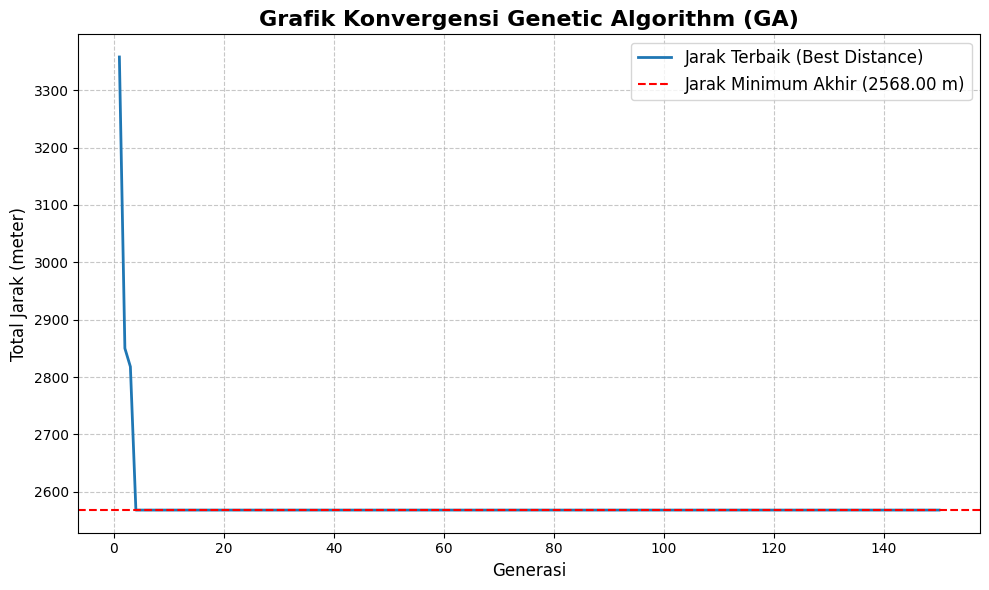

In [ ]:
if riwayat:
    plt.figure(figsize=(10, 6))
    generasi = np.arange(1, len(riwayat) + 1)
    plt.plot(generasi, riwayat, color='#1f77b4', lw=2, label='Jarak Terbaik (Best Distance)')
    plt.axhline(y=jarak_terbaik_ga, color='red', linestyle='--',
                label=f'Jarak Minimum Akhir ({jarak_terbaik_ga:.2f} m)')
    plt.title('Grafik Konvergensi Genetic Algorithm (GA)', fontsize=16, weight='bold')
    plt.xlabel('Generasi', fontsize=12)
    plt.ylabel('Total Jarak (meter)', fontsize=12)
    plt.grid(True, linestyle='--', alpha=0.7)
    plt.legend(fontsize=12)
    plt.tight_layout()
    plt.show()
else:
    print("Data riwayat kosong. Pastikan Anda sudah menjalankan Cell 7.")

## Path finding Visualization

In [ ]:
def get_path(p1, p2):
    x1, y1 = p1
    x2, y2 = p2

    ya1, off1, a1, b1 = access(x1, y1)
    ya2, off2, a2, b2 = access(x2, y2)

    axi, bxi = NAV[a1][0], NAV[b1][0]
    axj, bxj = NAV[a2][0], NAV[b2][0]

    if ya1 == ya2 and axi == axj:
        return [(x1, y1), (x1, ya1), (x2, ya1), (x2, y2)]

    best_d = float('inf')
    best_path = []

    for ei, exi in ((a1, axi), (b1, bxi)):
        for ej, exj in ((a2, axj), (b2, bxj)):
            d = abs(x1 - exi) + D_MATRIX[IDX[ei], IDX[ej]] + abs(x2 - exj)
            if d < best_d:
                best_d = d
                dist, prev, pq = {ei: 0}, {}, [(0, ei)]
                while pq:
                    du, u = heapq.heappop(pq)
                    if u == ej: break
                    if du > dist.get(u, float('inf')): continue
                    for v_idx, w in ADJ[IDX[u]]:
                        v = LABELS[v_idx]
                        if du + w < dist.get(v, float('inf')):
                            dist[v] = du + w; prev[v] = u
                            heapq.heappush(pq, (du + w, v))
                if ej not in dist: continue
                p = [ej]
                while p[-1] != ei: p.append(prev[p[-1]])
                p = p[::-1]

                path = [(x1, y1), (x1, ya1), (exi, ya1)]
                for node in p:
                    if NAV[node] not in path: path.append(NAV[node])
                if (exj, ya2) not in path: path.append((exj, ya2))
                path.append((x2, ya2))
                path.append((x2, y2))
                best_path = path
    return best_path

## Route Visualization

In [ ]:
def visualisasikan_rute(rute_terbaik, nama_algoritma, jarak_terbaik):
    koordinat_rute_lengkap = [depot] + [titik_kunjungan[idx] for idx in rute_terbaik] + [depot]
    rute_nama_lokasi = df_rute.iloc[rute_terbaik]['originalLocation'].tolist()
    print(f"\n--- Rute {nama_algoritma} ---")
    print(f"Rute Kunjungan: {' -> '.join(['DEPOT'] + rute_nama_lokasi + ['DEPOT'])}")
    df_pos_floor = df_storage_location
    df_sup_floor = df_support_point[df_support_point['Z'] == 1.0]
    fig_width, fig_height = 30, 20
    fig, ax = plt.subplots(figsize=(fig_width, fig_height))
    for _, row in df_pos_floor.iterrows():
        x, y = row['x'], row['y']
        block_width = 15
        xmin, xmax = x - block_width / 2, x + block_width / 2
        ymin, ymax = y - 15, y + 15

        rect = plt.Rectangle((xmin, ymin), block_width, 30, edgecolor='black', facecolor='white', alpha=0.5, linewidth=1)
        ax.add_patch(rect)
    if not df_sup_floor.empty:
        support_x = df_sup_floor['X']
        support_y = df_sup_floor['Y']
        support_labels = df_sup_floor['labels']
        ax.scatter(support_x, support_y, color='lightgray', s=50, label='Support Points', zorder=2)
        for i, label in enumerate(support_labels):
            ax.text(support_x.iloc[i] + 5, support_y.iloc[i], label, fontsize=10, color='gray')
        for y_val in df_sup_floor['Y'].unique():
            points_on_y = df_sup_floor[df_sup_floor['Y'] == y_val].sort_values(by='X')
            if len(points_on_y) > 1:
                ax.plot(points_on_y['X'], points_on_y['Y'], color='lightgray', linestyle='--', linewidth=1, zorder=1)
        for x_val in df_sup_floor['X'].unique():
            points_on_x = df_sup_floor[df_sup_floor['X'] == x_val].sort_values(by='Y')
            if len(points_on_x) > 1:
                ax.plot(points_on_x['X'], points_on_x['Y'], color='lightgray', linestyle='--', linewidth=1, zorder=1)
    ax.scatter(depot[0], depot[1], color='green', s=400, marker='*', zorder=5, label='DEPOT')
    ax.text(depot[0], depot[1]+20, 'DEPOT (Start/End)', color='green', weight='bold', fontsize=12, ha='center',
            bbox=dict(facecolor='white', edgecolor='green', boxstyle='round,pad=0.2', alpha=0.8))
    for i in range(len(koordinat_rute_lengkap) - 1):
        p1 = koordinat_rute_lengkap[i]
        p2 = koordinat_rute_lengkap[i+1]
        path = get_path((p1[0], p1[1]), (p2[0], p2[1]))
        if not path:
            path = [(p1[0], p1[1]), (p2[0], p1[1]), (p2[0], p2[1])]
        xs = [p[0] for p in path]
        ys = [p[1] for p in path]
        ax.plot(xs, ys, color='red', ls='-', lw=2.5, alpha=0.8, zorder=3)
        for k in range(len(path)-1):
            if path[k] == path[k+1]: continue
            mid_x = (path[k][0] + path[k+1][0]) / 2
            mid_y = (path[k][1] + path[k+1][1]) / 2
            dx = path[k+1][0] - path[k][0]
            dy = path[k+1][1] - path[k][1]
            length = np.hypot(dx, dy)
            if length > 20:
                dx /= length
                dy /= length
                ax.annotate('', xy=(mid_x + dx*5, mid_y + dy*5), xytext=(mid_x - dx*5, mid_y - dy*5),
                            arrowprops=dict(arrowstyle="->, head_width=0.5, head_length=0.7",
                                            color='red', lw=2.5, alpha=0.8),
                            zorder=4)
    for step_idx, p in enumerate(koordinat_rute_lengkap):
        if step_idx > 0 and step_idx < len(koordinat_rute_lengkap)-1:
            ax.text(p[0], p[1] + 25, f'Step {step_idx}', color='white', fontsize=10, weight='bold', ha='center',
                    bbox=dict(facecolor='red', edgecolor='darkred', boxstyle='round,pad=0.3', alpha=0.9), zorder=5)
    ax.set_xticks([])
    ax.set_yticks([])

    margin = 100
    ax.set_xlim(df_pos_floor['x'].min() - margin, df_pos_floor['x'].max() + margin)
    ax.set_ylim(df_pos_floor['y'].min() - margin, df_pos_floor['y'].max() + margin)

    plt.title(f"Visualisasi Rute ({nama_algoritma}) via Lorong | Wave {wave_terpilih} | Z=1\nTotal Jarak = {jarak_terbaik:.2f} m", fontsize=18, weight='bold')

    red_line = mlines.Line2D([], [], color='red', marker='>', linestyle='-', lw=2.5, label='Rute Kunjungan (Lorong)')
    depot_marker = mlines.Line2D([], [], color='green', marker='*', linestyle='None', markersize=15, label='Depot / Titik Awal')
    ax.legend(handles=[red_line, depot_marker], loc='upper right', fontsize=12)

    plt.show()

## RUN ALL HELL NAH


--- Rute Genetic Algorithm (GA) ---
Rute Kunjungan: DEPOT -> M-13-11 -> P-09-13 -> P-14-12 -> O-17-11 -> O-13-12 -> O-13-11 -> M-04-13 -> K-16-11 -> K-16-12 -> DEPOT


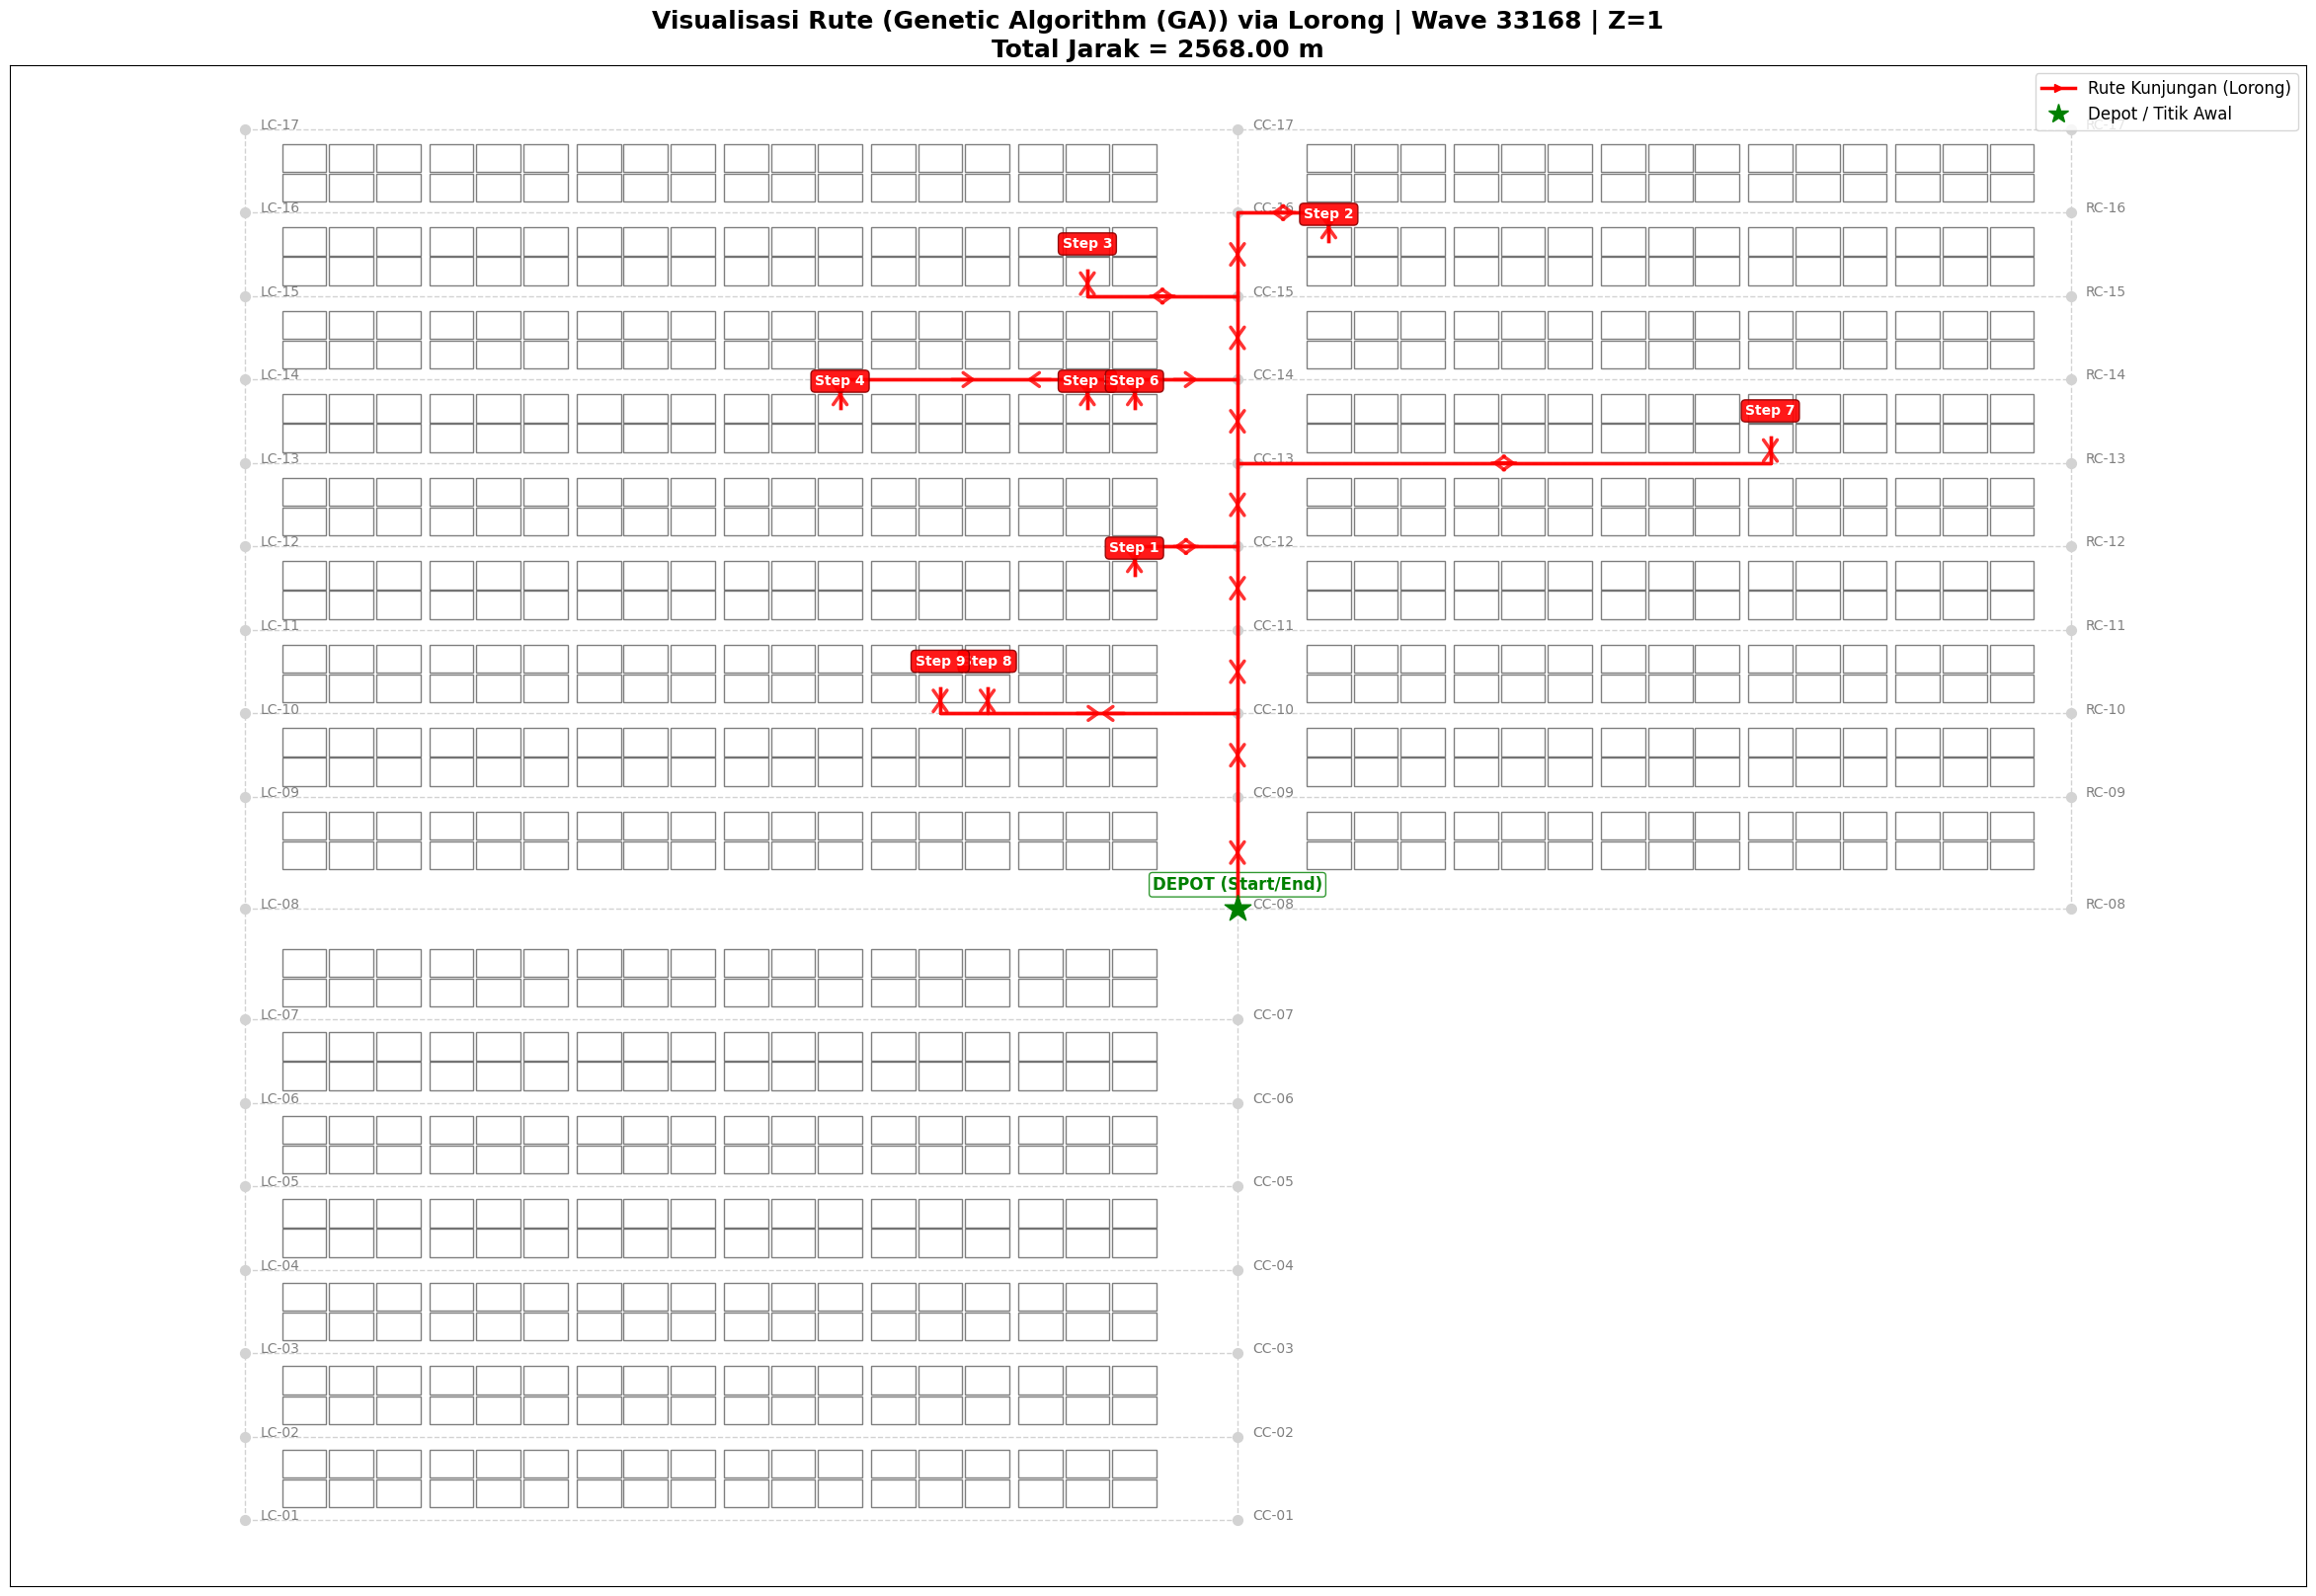


--- Rute Nearest Neighbor (NN) ---
Rute Kunjungan: DEPOT -> K-16-11 -> K-16-12 -> M-13-11 -> O-13-11 -> O-13-12 -> O-17-11 -> P-14-12 -> P-09-13 -> M-04-13 -> DEPOT


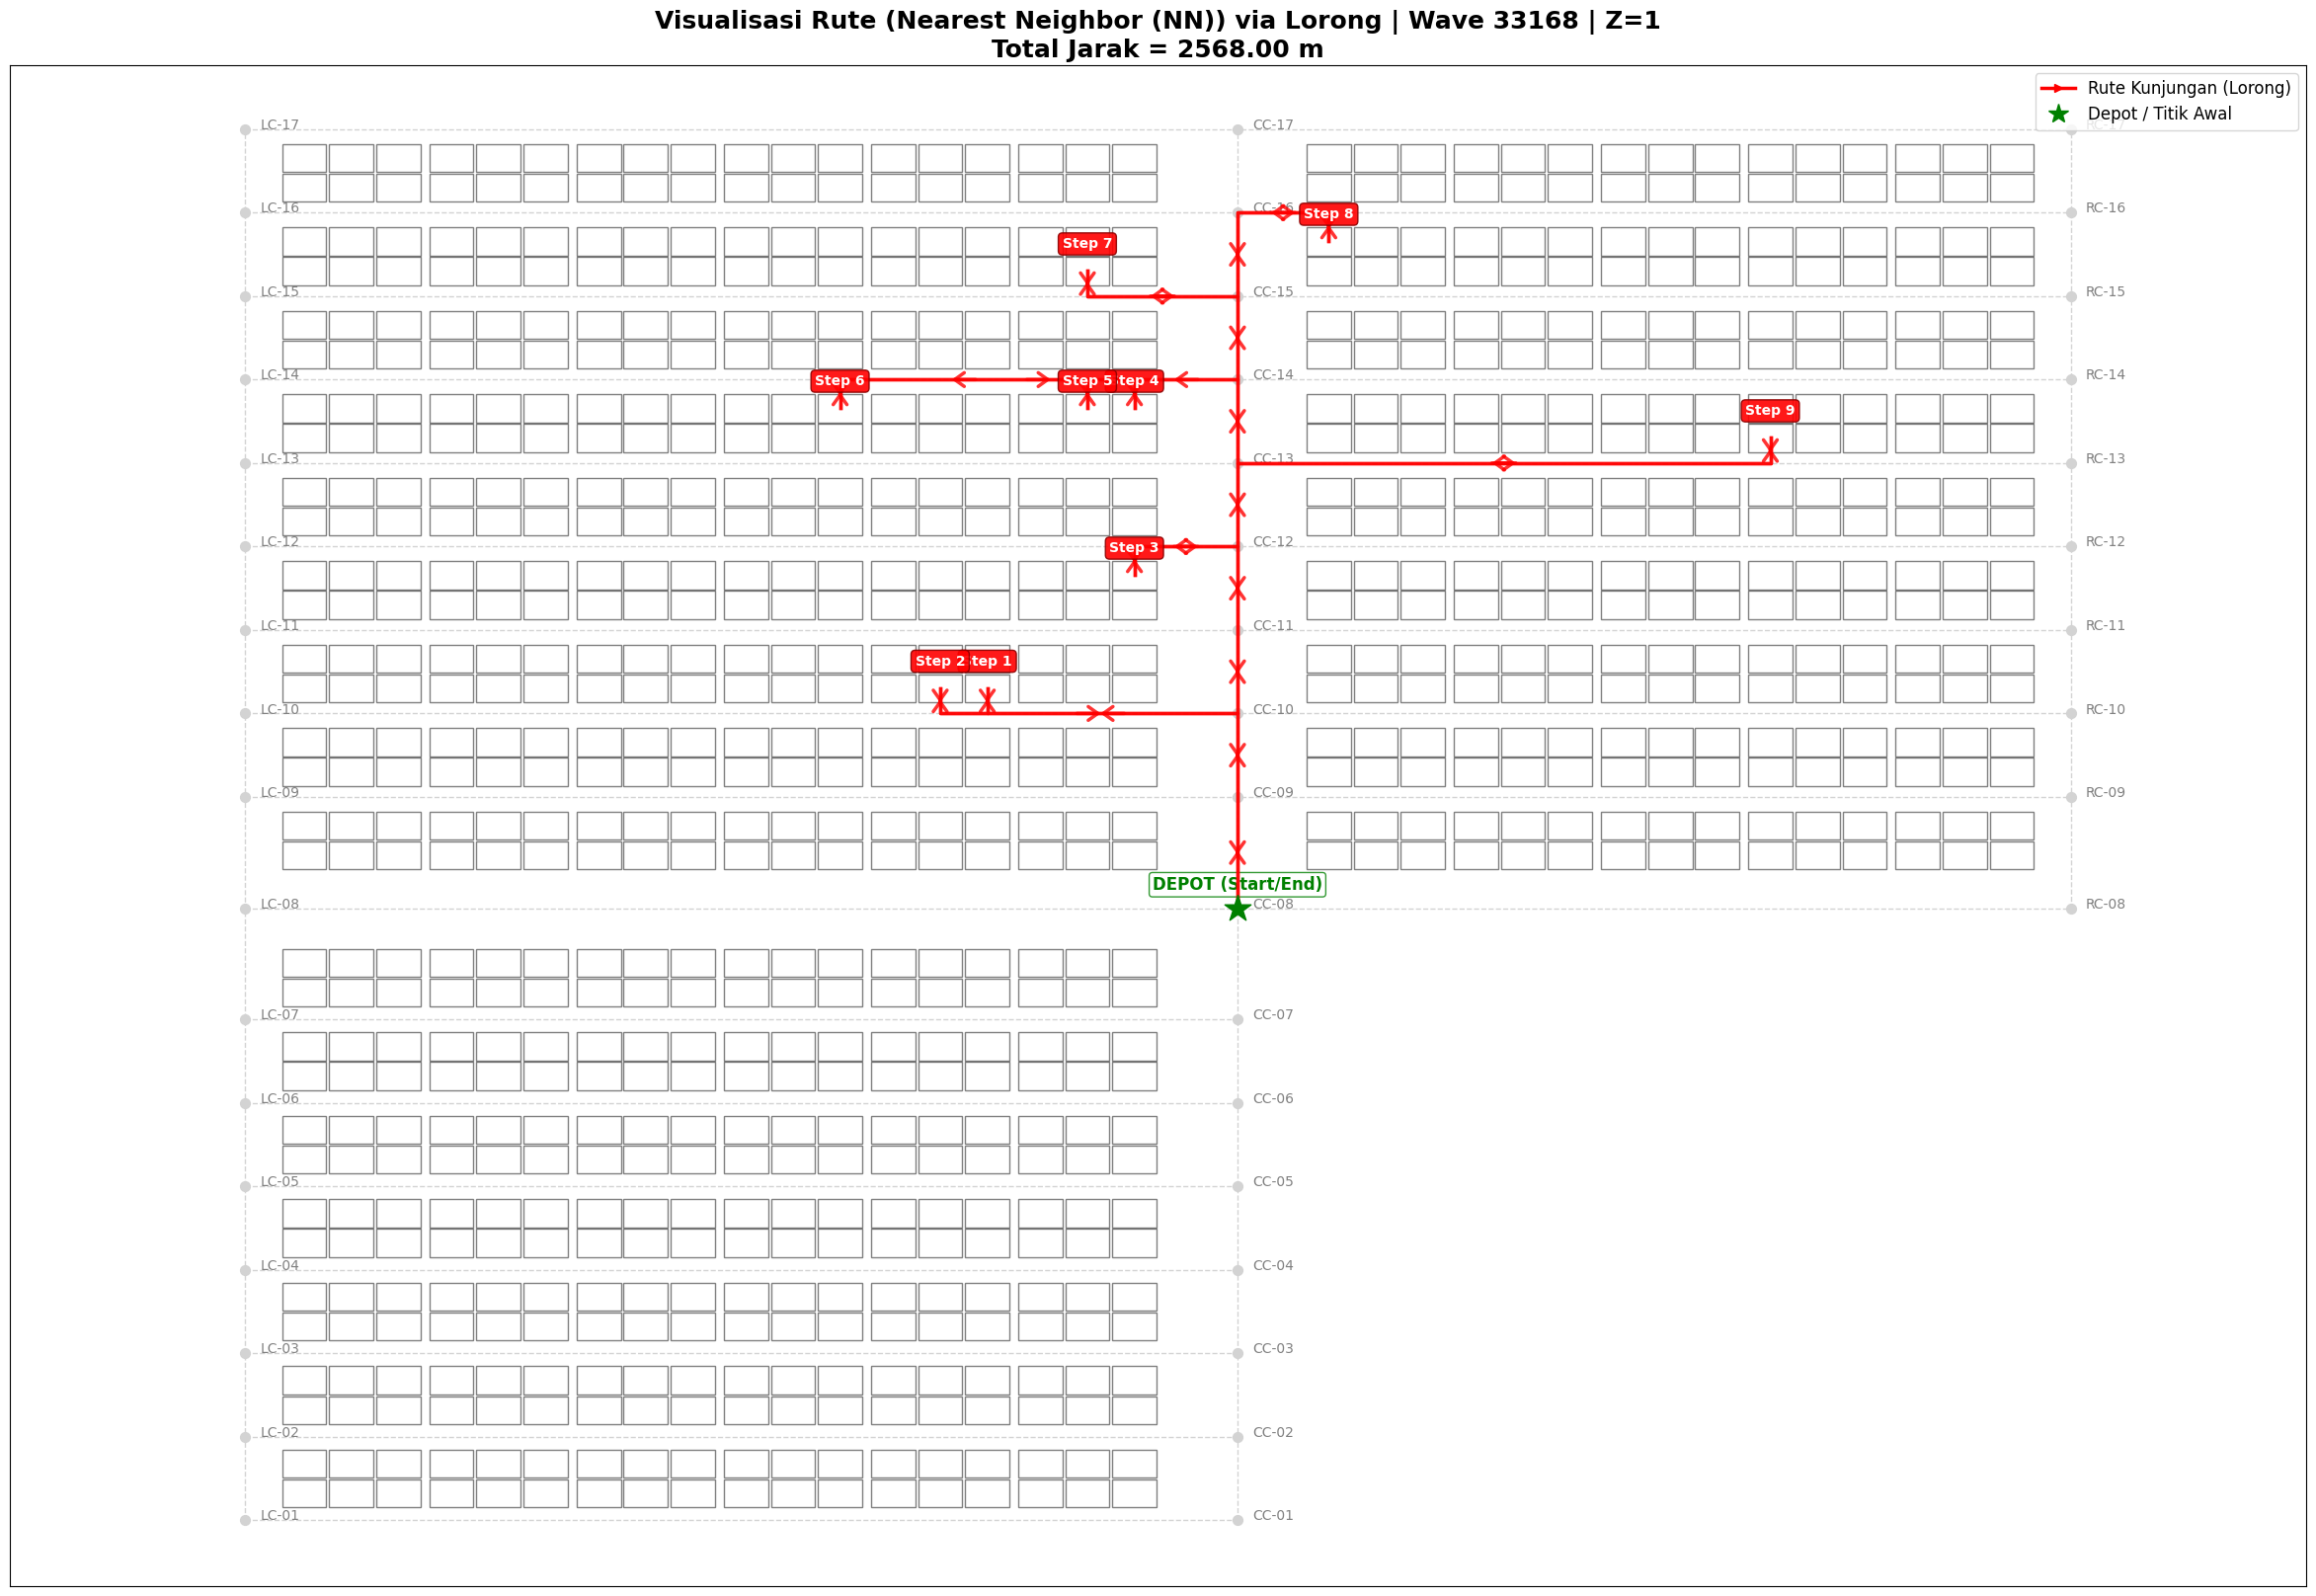


--- Rute Rute Awal (Tanpa Optimasi) ---
Rute Kunjungan: DEPOT -> P-09-13 -> P-14-12 -> O-17-11 -> O-13-12 -> O-13-11 -> M-13-11 -> M-04-13 -> K-16-12 -> K-16-11 -> DEPOT


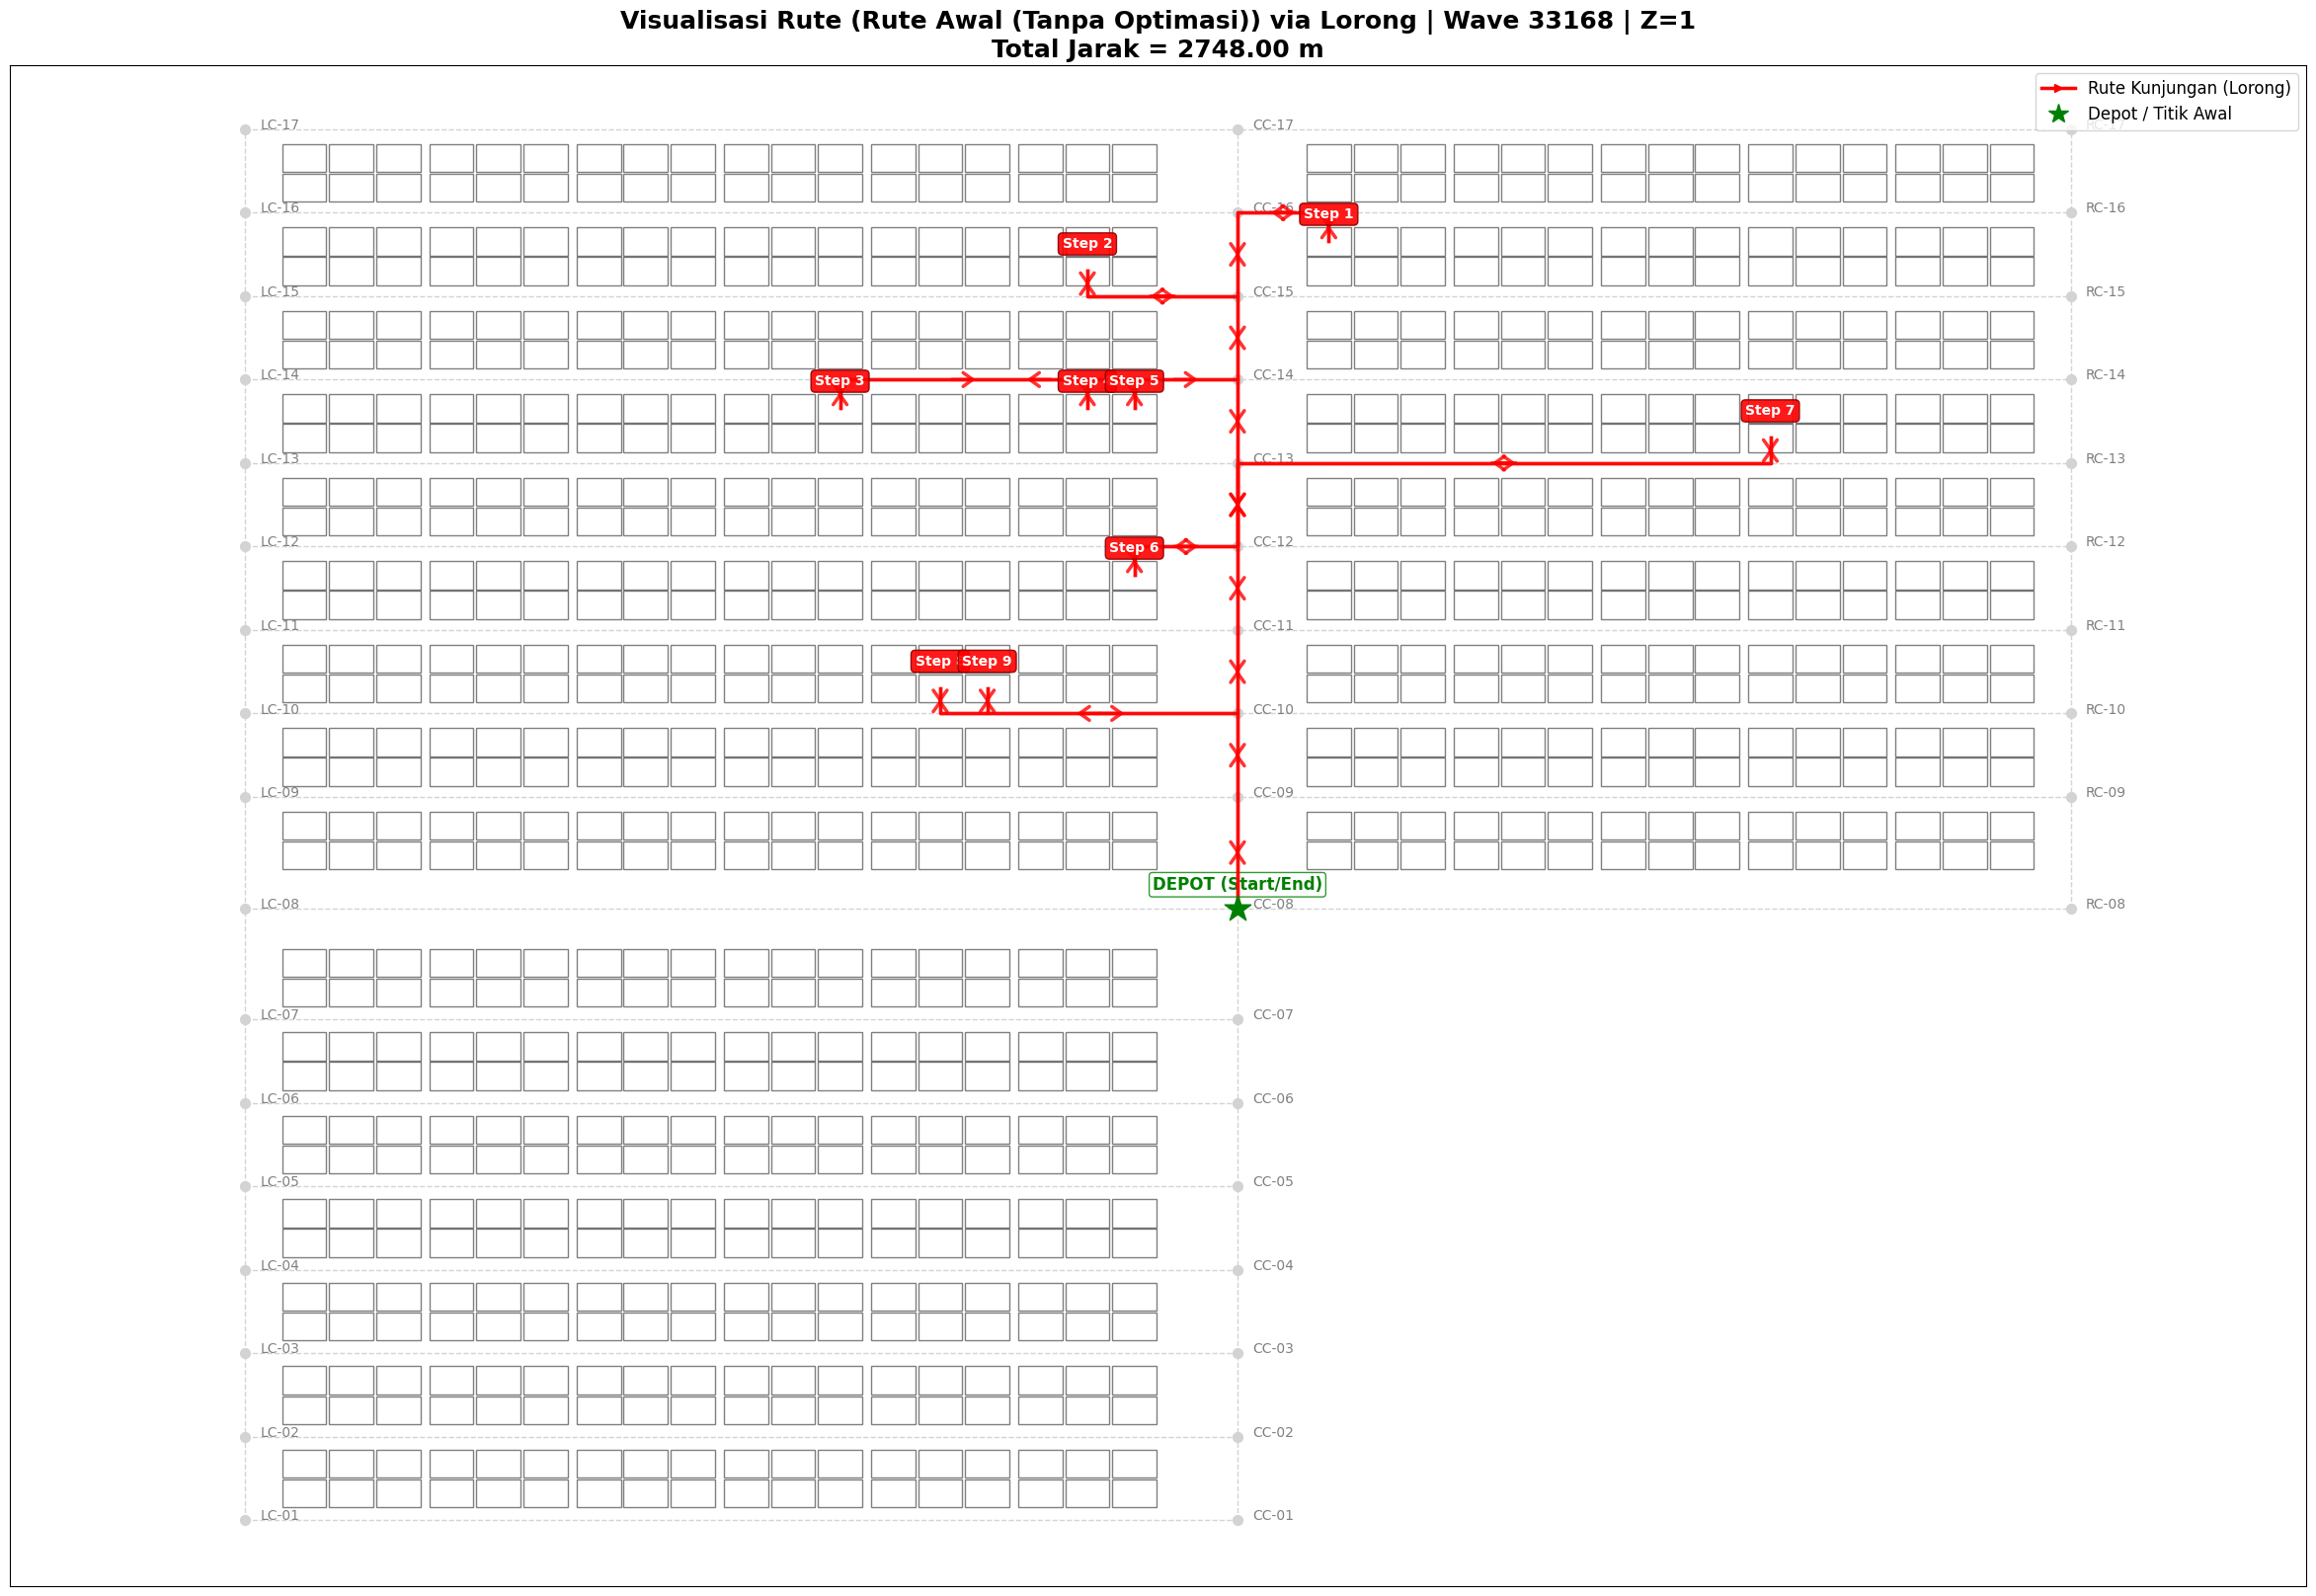

In [ ]:
visualisasikan_rute(rute_terbaik_ga, "Genetic Algorithm (GA)", jarak_terbaik_ga)
visualisasikan_rute(rute_terbaik_nn, "Nearest Neighbor (NN)", jarak_terbaik_nn)
visualisasikan_rute(rute_awal, "Rute Awal (Tanpa Optimasi)", jarak_awal)